# Icelandic LLM: обучение с нуля


In [1]:
import os
import sys

ROOT = os.path.abspath("..")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
os.chdir(ROOT)  

import torch  

print("ROOT:", ROOT)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    name = torch.cuda.get_device_name(0)
    mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU: {name}, {mem:.1f} GB, bf16={torch.cuda.is_bf16_supported()}")

ROOT: /home/jovyan/work/isllm
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti, 16.6 GB, bf16=True


## Датасет: Icelandic Gigaword Corpus (IGC2024 Filtered-1)

Скачать датасет:

```
wget "https://repository.clarin.is/repository/xmlui/bitstream/handle/20.500.12537/381/igc2024-1-filtered.zip?sequence=1&isAllowed=y" -O igc2024-1-filtered.zip
```

Скачанный датасет находится в isllm/data/raw

## Очистка и подготовка

- `clean_text`: удаление HTML-тегов, XML-сущностей, URL, управляющих символов, нормализация пробелов и пунктуации;
- `is_icelandic_doc`: проверка что текст содержит преимущественно исландские буквы, длина текста больше 80 символов, удаление таблиц;
- `dedup_docs`: удаление копий текста;
- `split_docs`: разделение на тренировочный и валидационный датасеты.

Очищенный датасет находится в isllm/data/prepared

## Статистика и примеры текстов 

1.8 млн документов в тренировочной выборке (всего 4 млрд символов) и 18 тыс документов в валидационной (всего 46 млн символов)

По примерам текстов можно видеть что тексты хорошо очищенные, качественные, подходящие для обучения.

In [2]:
import json
import sys
import os

current_dir = os.getcwd()
if current_dir.endswith('notebooks'):
    project_root = os.path.abspath('..')
else:
    project_root = os.path.abspath('.')

if project_root not in sys.path:
    sys.path.append(project_root)

from isllm.data import (
    clean_text,
    corpus_stats,
    dedup_docs,
    is_icelandic_doc,
    iter_igc_docs,
    write_docs,
)

TRAIN_PATH = os.path.join(project_root, "data/raw/igc2024-1-filtered-train.jsonl")
VAL_PATH = os.path.join(project_root, "data/raw/igc2024-1-filtered-val.jsonl")

PREPARED_DIR = os.path.join(project_root, "data/prepared")
TRAIN_OUT = os.path.join(PREPARED_DIR, "train.txt")
VAL_OUT = os.path.join(PREPARED_DIR, "val.txt")
STATS_OUT = os.path.join(PREPARED_DIR, "stats.json")

FILTER = dict(min_len=80, min_lat=0.8, min_ice_spec=0.002, max_digits=0.15)


def process_file(file_path, do_dedup=False):
    """Читает и фильтрует файл, возвращает список документов и статистику."""
    docs = []
    rejected = {}
    n_scanned = 0
    
    for n_scanned, text in enumerate(iter_igc_docs(file_path), start=1):
        clean = clean_text(text)
        ok, reason = is_icelandic_doc(clean, **FILTER)
        if ok:
            docs.append(clean)
        else:
            rejected[reason] = rejected.get(reason, 0) + 1

    removed = 0
    if do_dedup:
        docs, removed = dedup_docs(docs)
        
    return docs, n_scanned, rejected, removed


def load_doc_samples(path, max_docs=3):
    """Потоково считывает первые N документов из файла, разделенных пустой строкой."""
    docs = []
    current_doc = []
    
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                if current_doc:
                    docs.append("\n".join(current_doc))
                    current_doc = []
                    if len(docs) >= max_docs:
                        break
            else:
                current_doc.append(line)
                
    if current_doc and len(docs) < max_docs:
        docs.append("\n".join(current_doc))
        
    return docs



    
if os.path.exists(TRAIN_OUT) and os.path.exists(VAL_OUT) and os.path.exists(STATS_OUT):
    print("Обнаружены ранее подготовленные файлы. Загрузка статистики...")
    
    with open(STATS_OUT, "r", encoding="utf-8") as f:
        stats = json.load(f)
        
else:
    print("Подготовленные данные не найдены. Запуск обработки...")
    os.makedirs(PREPARED_DIR, exist_ok=True)
    
    if not os.path.exists(TRAIN_PATH):
        raise FileNotFoundError(f"Файл не найден: {TRAIN_PATH}")
    if not os.path.exists(VAL_PATH):
        raise FileNotFoundError(f"Файл не найден: {VAL_PATH}")

    print("Обработка train...")
    train_docs, train_scanned, train_rejected, train_removed = process_file(TRAIN_PATH)
    print(f"Train: всего {train_scanned} | принято: {len(train_docs)} | удалено дублей: {train_removed}")
    
    print("Обработка val...")
    val_docs, val_scanned, val_rejected, val_removed = process_file(VAL_PATH)
    print(f"Val: всего {val_scanned} | принято: {len(val_docs)} | удалено дублей: {val_removed}")

    write_docs(train_docs, TRAIN_OUT)
    write_docs(val_docs, VAL_OUT)

    stats = {
        "corpus": {"train": TRAIN_PATH, "val": VAL_PATH},
        "train": {
            "raw_docs": train_scanned,
            "accepted": len(train_docs),
            "removed_duplicates": train_removed,
            "reject_reasons": train_rejected,
            "stats": corpus_stats(train_docs)
        },
        "val": {
            "raw_docs": val_scanned,
            "accepted": len(val_docs),
            "removed_duplicates": val_removed,
            "reject_reasons": val_rejected,
            "stats": corpus_stats(val_docs)
        }
    }

    with open(STATS_OUT, "w", encoding="utf-8") as f:
        json.dump(stats, f, ensure_ascii=False, indent=2)

print("\n--- ИТОГОВАЯ СТАТИСТИКА ---")
print("Train:", stats["train"]["stats"]["n_docs"], "docs,", stats["train"]["stats"]["n_chars"], "chars")
print("Val:", stats["val"]["stats"]["n_docs"], "docs,", stats["val"]["stats"]["n_chars"], "chars")

print("\nПримеры документов из train:")
sample_train = load_doc_samples(TRAIN_OUT, max_docs=10)
for i, doc in enumerate(sample_train, 1):
    print(f"\n--- Train документ {i} ({len(doc)} симв.) ---")
    print(doc[:1000] + "..." if len(doc) > 1000 else doc)

print("\nПримеры документов из val:")
sample_val = load_doc_samples(VAL_OUT, max_docs=10)
for i, doc in enumerate(sample_val, 1):
    print(f"\n--- Val документ {i} ({len(doc)} симв.) ---")
    print(doc[:1000] + "..." if len(doc) > 1000 else doc)



Обнаружены ранее подготовленные файлы. Загрузка статистики...

--- ИТОГОВАЯ СТАТИСТИКА ---
Train: 1823200 docs, 4631914160 chars
Val: 18561 docs, 46742984 chars

Примеры документов из train:

--- Train документ 1 (8259 симв.) ---
Hugbúnaðarfyrirtækið EC, fól G sem verktaka að flytja hýsingu léna af netþjónum EC til ANZA hf., en til stóð að síðarnefnda fyrirtækið tæki yfir hýsingarþjónustu fyrir EC. Málsaðilar deildu um hvort tæknilegir örðugleikar hefðu komið upp við flutning lénanna. G taldi sér heimilt, vegna örðugleika sem upp komu, að flytja gögnin yfir á netþjóna sína og hýsa lénin fyrir EC gagn gjaldi. Gegn andmælum EC var ekki talið að G hefði tekist sönnun um að honum hefði verið heimilt á grundvelli munnlegs samkomulags við EC að flytja umrædd gögn á ný frá ANZA hf., yfir á eigin netþjóna og annast hýsingu fyrir EC gegn gjaldi. Þá liggur fyrir í gögnum málsins að G hefði hótað EC að loka aðgangi að öllu sem hann hýsti fyrir EC yrðu reikningar ekki greiddir sem hefði leitt af s

## 3. Статистика и графики корпуса

Подробная статистика в isllm/data/prepared/stats.json


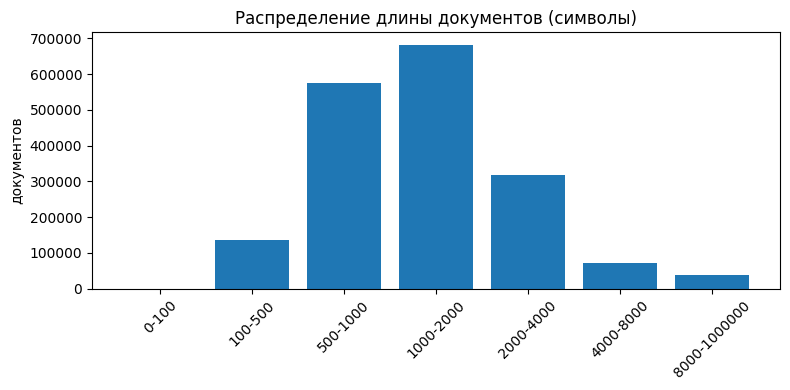

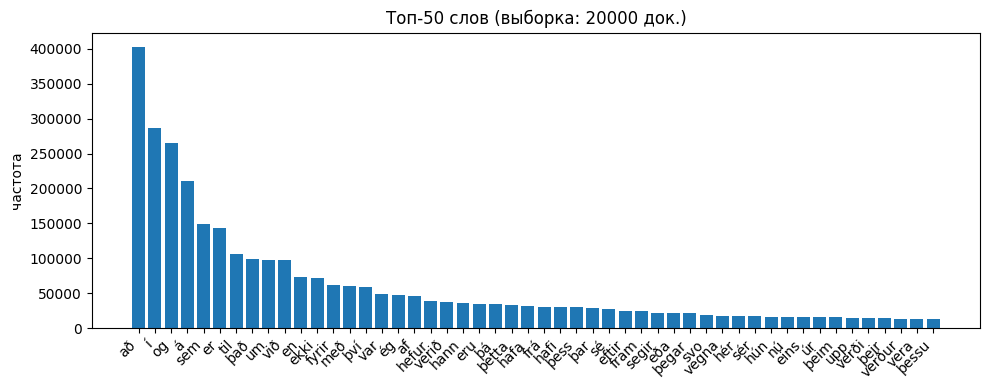

train docs: 1823200 | words: 736668761 | уникальных слов: 37291459


In [3]:
import matplotlib.pyplot as plt

train_stats = stats["train"]["stats"]

# Гистограмма длин документов 
hist = train_stats.get("doc_len_hist", [])
if hist:
    labels = [h["range"] for h in hist]
    counts = [h["count"] for h in hist]
    plt.figure(figsize=(8, 4))
    plt.bar(range(len(counts)), counts)
    plt.xticks(range(len(counts)), labels, rotation=45)
    plt.ylabel("документов")
    plt.title("Распределение длины документов (символы)")
    plt.tight_layout()
    plt.show()

# Топ-50 слов по частоте 
top = train_stats.get("top_words", [])
if top:
    words = [w for w, _ in top]
    freqs = [f for _, f in top]
    plt.figure(figsize=(10, 4))
    plt.bar(range(len(freqs)), freqs)
    plt.xticks(range(len(words)), words, rotation=45, ha="right")
    plt.ylabel("частота")
    plt.title(f"Топ-{len(words)} слов (выборка: {train_stats.get('word_stats_sample', '?')} док.)")
    plt.tight_layout()
    plt.show()

print("train docs:", train_stats["n_docs"], "| words:", train_stats["n_words"],
      "| уникальных слов:", train_stats["unique_words"])

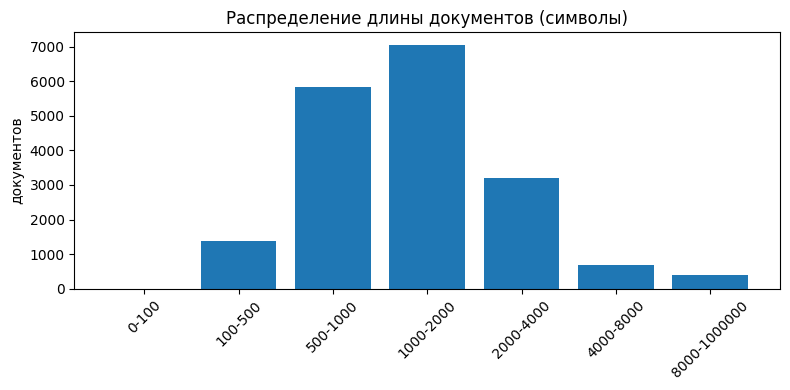

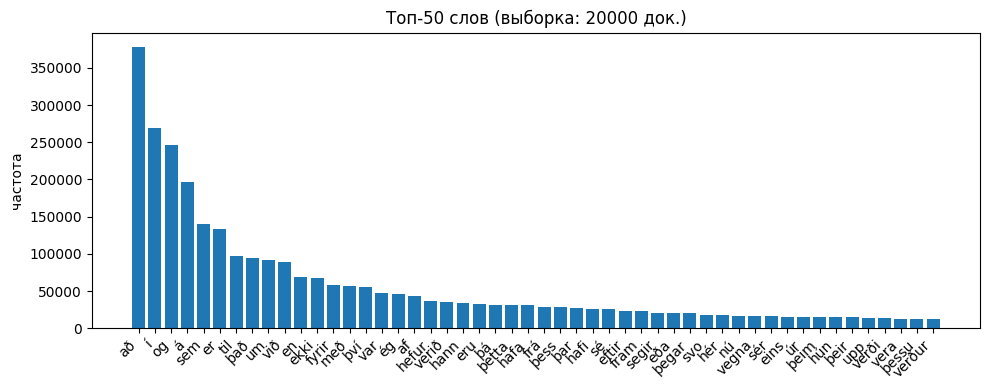

val docs: 18561 | words: 7429694 | уникальных слов: 391682


In [4]:
import matplotlib.pyplot as plt

val_stats = stats["val"]["stats"]

# Гистограмма длин документов 
hist = val_stats.get("doc_len_hist", [])
if hist:
    labels = [h["range"] for h in hist]
    counts = [h["count"] for h in hist]
    plt.figure(figsize=(8, 4))
    plt.bar(range(len(counts)), counts)
    plt.xticks(range(len(counts)), labels, rotation=45)
    plt.ylabel("документов")
    plt.title("Распределение длины документов (символы)")
    plt.tight_layout()
    plt.show()

# Топ-50 слов по частоте 
top = val_stats.get("top_words", [])
if top:
    words = [w for w, _ in top]
    freqs = [f for _, f in top]
    plt.figure(figsize=(10, 4))
    plt.bar(range(len(freqs)), freqs)
    plt.xticks(range(len(words)), words, rotation=45, ha="right")
    plt.ylabel("частота")
    plt.title(f"Топ-{len(words)} слов (выборка: {train_stats.get('word_stats_sample', '?')} док.)")
    plt.tight_layout()
    plt.show()

print("val docs:", val_stats["n_docs"], "| words:", val_stats["n_words"],
      "| уникальных слов:", val_stats["unique_words"])

## Вывод по статистике корпуса

Видно, что в среднем длина документов 2.5 тыс символов (мода 1000-2000), короткие тексты были отсеяны. 
Видим, что наиболее частотные слова естественны: это частые глаголы, предлоги, союзы, а не разметка/цифры/английские слова. 
Статистика на валидационной выборке близка к статистике на тренировочной, не видно признаков сдвига распределений.

## 4. Токенизатор: сетка BPE и Unigram со словарями разных размеров.

**Основные отличия двух алгоритмов:**

- BPE строит словарь «снизу вверх», итеративно и жадно сливая самые частые пары символов, а Unigram начинает с избыточного словаря и «сверху вниз» удаляет токены, которые меньше всего увеличивают правдоподобие корпуса (то есть по сути он не оптимизирует длину кодировки на прямую).
- BPE при токенизации детерминированно применяет фиксированные правила слияния, тогда как Unigram вероятностно перебирает все возможные сегментации и выбирает ту, у которой максимальна суммарная вероятность;
- Плюс BPE это скорость, простота, детерминизм; минус - жадность может «размывать» морфологические границы;
- Плюс Unigram это более точное следование морфологии и лучшая производительность на языках со сложной морфологией, минус - вычислительно более сложное обучение;
- Наиболее часто в современных LLM применяется BPE, особенно байтовый вариант.

Обучаем 8 вариантов (2 алгоритма по 4 размера словаря) на подвыборке корпуса и сравниваем:
- **chars_per_token (fertility)** - сколько символов покрывает один токен;
- **tokens_per_word** - сколько в среднем токенов в 1 слове;
- **byte_fallback_rate** - доля байтовых токенов. То есть OOV слов, для которых произошло кодирование через байты;
- **roundtrip** - доля текстов, точно восстановленных после encode -> decode. В норме равен 1, иначе может сигнализировать о наличие символов не той кодировки, неоднозначной обработке спец символов и тд.

Для скорости сетка обучается на первых 1M символов. Финальный токенизатор будет обучен на полном корпусе.

In [5]:
import json
import pathlib

from isllm.tokenizer import (
    DEFAULT_ALGS,
    DEFAULT_VOCABS,
    evaluate_tokenizer,
    sample_texts,
    train_single,
)

pathlib.Path("tokenizer").mkdir(parents=True, exist_ok=True)
grid_inputs = ["tokenizer/_grid_sample.txt"]
pathlib.Path(grid_inputs[0]).write_text(
    "\n".join(sample_texts("data/prepared/train.txt", max_chars=2000000)),
    encoding="utf-8",
)

grid_metrics = []
for alg in DEFAULT_ALGS:
    for vs in DEFAULT_VOCABS:
        tok = train_single(f"tokenizer/{alg}_{vs}", input_files=grid_inputs,
                           alg=alg, vocab_size=vs, min_frequency=2,
                           byte_fallback=(alg == "bpe"))
        metrics = evaluate_tokenizer(
            tok,
            sample_texts("data/prepared/train.txt", max_chars=500000)[:5000],
            alg=alg,
        )
        metrics.update({"alg": alg, "vocab_size": vs})
        grid_metrics.append(metrics)
        bf = metrics["byte_fallback_rate"]
        print(f"{alg}_{vs}: fert={metrics['chars_per_token']:.2f} "
              f"tok/w={metrics['tokens_per_word']:.2f} "
              f"bytefb={'n/a' if bf is None else f'{bf:.3f}'} "
              f"round={metrics['roundtrip_accuracy']:.3f}")

with open("tokenizer/grid_results.json", "w", encoding="utf-8") as f:
    json.dump(grid_metrics, f, ensure_ascii=False, indent=2)

print("\nСводка:")
print(f"{'name':<18}{'fert':>7}{'tok/w':>7}{'bytefb':>8}{'round':>8}")
for r in grid_metrics:
    bf = r["byte_fallback_rate"]
    bf_s = "n/a" if bf is None else f"{bf:.3f}"
    print(f"{r['alg']}_{r['vocab_size']:<14}{r['chars_per_token']:7.2f}"
          f"{r['tokens_per_word']:7.2f}{bf_s:>8}{r['roundtrip_accuracy']:8.3f}")




bpe_8192: fert=3.97 tok/w=1.55 bytefb=0.000 round=1.000



bpe_16384: fert=4.46 tok/w=1.38 bytefb=0.000 round=1.000



bpe_32768: fert=4.94 tok/w=1.25 bytefb=0.000 round=1.000



bpe_65536: fert=4.98 tok/w=1.24 bytefb=0.000 round=1.000


unigram_8192: fert=3.56 tok/w=1.73 bytefb=n/a round=1.000


unigram_16384: fert=3.85 tok/w=1.60 bytefb=n/a round=1.000


unigram_32768: fert=3.97 tok/w=1.55 bytefb=n/a round=1.000


unigram_65536: fert=3.97 tok/w=1.55 bytefb=n/a round=1.000

Сводка:
name                 fert  tok/w  bytefb   round
bpe_8192             3.97   1.55   0.000   1.000
bpe_16384            4.46   1.38   0.000   1.000
bpe_32768            4.94   1.25   0.000   1.000
bpe_65536            4.98   1.24   0.000   1.000
unigram_8192             3.56   1.73     n/a   1.000
unigram_16384            3.85   1.60     n/a   1.000
unigram_32768            3.97   1.55     n/a   1.000
unigram_65536            3.97   1.55     n/a   1.000


## Выводы по токенизаторам

- **BPE выигрывает** по сжатию при всех размерах словаря. То есть с помощью BPE один и тот же текст будет закодирован меньшим количеством токенов сравнительно с Unigram.

  Рассчитаем количество параметров в матрице эмбеддингов: vocab_size * d_model. У нас будут tied embeddings. d_model возьмем 512.

  
| vocab_size | примерно параметров | доля от 45M (при мерно столько будет в итоговой модели) |
|-----------:|--------------------:|-------------:|
|      8 192 |               4.2M  |           9% |
|     16 384 |               8.4M  |          19% |
|     32 768 |              16.8M  |          37% |
|     65 536 |              33.6M  |          75% |


В общем, решено было взять размер словаря 16384 и алгоритм BPE 

## Финальный токенизатор и бинаризация корпуса

In [6]:
import os
import json
from isllm.tokenizer import prepare_bins, train_single, load_tokenizer

BEST_ALG = "bpe"
BEST_VS = 16384
TOKENIZER_PATH = "tokenizer/final"
BINS_DIR = "data/bins"
META_PATH = os.path.join(BINS_DIR, "meta.json")

if os.path.exists(os.path.join(TOKENIZER_PATH, "tokenizer.json")):
    print(f"Обнаружен ранее обученный токенизатор. Загрузка из {TOKENIZER_PATH}...")
    final_tok = load_tokenizer(TOKENIZER_PATH)
else:
    print("Токенизатор не найден. Запуск обучения на полном корпусе...")
    final_tok = train_single(
        TOKENIZER_PATH,
        input_files=["data/prepared/train.txt"],
        alg=BEST_ALG,
        vocab_size=BEST_VS,
        min_frequency=2,
        byte_fallback=True,
    )
print("Финальный токенизатор:", TOKENIZER_PATH, "| vocab_size:", len(final_tok.get_vocab()))

if os.path.exists(META_PATH) and os.path.exists(os.path.join(BINS_DIR, "train.bin")) and os.path.exists(os.path.join(BINS_DIR, "val.bin")):
    print(f"Обнаружены готовые бинарные файлы. Загрузка метаданных из {META_PATH}...")
    with open(META_PATH, "r", encoding="utf-8") as f:
        meta = json.load(f)
else:
    print("Бинарные файлы не найдены. Запуск токенизации корпуса...")
    meta = prepare_bins(
        TOKENIZER_PATH,
        outdir=BINS_DIR,
        train_file="data/prepared/train.txt",
        val_file="data/prepared/val.txt",
    )

print("vocab_size:", meta["vocab_size"])
print("n_train_tokens:", meta["n_train_tokens"], "| n_val_tokens:", meta["n_val_tokens"])

Обнаружен ранее обученный токенизатор. Загрузка из tokenizer/final...
Финальный токенизатор: tokenizer/final | vocab_size: 16384
Обнаружены готовые бинарные файлы. Загрузка метаданных из data/bins/meta.json...
vocab_size: 16384
n_train_tokens: 1049773167 | n_val_tokens: 10602775


## Обучение модели

**Конфигурация модели:**

```
  arch: mistral
  n_layer: 12
  n_embd: 512
  n_head: 8
  seq_len: 1024
  vocab_size: 16384
  tie_word_embeddings: true
  dropout: 0.0
```
Примерно **45М** обучаемых параметров. Инициализируются случайно. 

Обучается decoder-only Mistral из HF Transformers. Внутри каждого слоя: 

- **RMSNorm**,
- **SDPA causal self-attention с RoPE**,
- **SwiGLU MLP**, 
- **tied_embeddings**.

Что можно добавить, но пока нет:
- **GQA** включается через `num_key_value_heads`, сейчас отключен.
- **Dropout** в данном запуске отключен.  


**Параметры обучения**:

```
  batch_size: 8
  grad_accum: 4
  grad_clip: 1.0
  lr: 1e-4                 
  warmup_steps: 1000    
  weight_decay: 0.1
  max_steps: 150000
  eval_every: 500
  save_every: 1000
  gen_every: 1000
  save_total_limit: 2
  seed: 42
  amp: bf16
  grad_checkpointing: true
  num_workers: 0
```

**Используемые техники**:

- Оптимизатор: **AdamW**;

- **weight_decay=0.1** - L2-регуляризация на веса;

- **Cosine LR schedule** плавно снижает LR по косинусу от lr до близкому к 0 к концу; стабилизирует позднюю стадию обучения;

- **warmup_steps=1000** - линейный разогрев LR в начале, чтобы не испортить случайно инициализированные веса большими шагами;

- **max_grad_norm=1.0** - gradient clipping: обрезает норму градиента, защищает от взрывов;

- **grad_accum=4** - накапливает градиенты 4 микробатчей перед шагом, что дает эффективный батч 32 без роста памяти;

- **bf16 autocast** - forward/backward в bf16, master-веса в fp32 - численная стабильность **mixed precision**;

- **Gradient checkpointing** - не хранит активации, а пересчитывает их на backward, что дает экономию памяти ценой;

- **SDPA attention** для быстроты вычисления.


[train] vocab_size из meta.json: 16384


`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


[train] arch=mistral, параметров: 89.13M


max_steps is given, it will override any value given in num_train_epochs
The `train_sampling_strategy='random'` option is ignored when using an `IterableDataset`. Samplers cannot be used with IterableDataset as they require indexed access to the dataset.
***** Running training *****
  Num examples = 4,800,000
  Num Epochs = 9,223,372,036,854,775,807
  Num update steps per epoch = 150,000
  Instantaneous batch size per device = 4
  Total train batch size (w. parallel, distributed & accumulation) = 32
  Gradient Accumulation steps = 8
  Total optimization steps = 150,000
  Number of trainable parameters = 89,129,600



[Step    500] Loss: 8.6234 | LR: 1.25e-05 | GradNorm: 0.10 | Time: 00:17:14



***** Running Evaluation *****
  Num examples = 500
  Batch size = 1


... (1,546 outputs left out)


[!] Обучение прервано пользователем. Сохранение текущего состояния...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model weights saved in checkpoints/large/checkpoint_interrupted/model.safetensors


[!] Состояние сохранено в checkpoints/large/checkpoint_interrupted

Итог обучения:
{
  "best_val": null,
  "final_train_loss": null,
  "steps": 129450,
  "model_size_m": 89.1296,
  "device": "cuda",
  "elapsed": 273684.6028084755
}


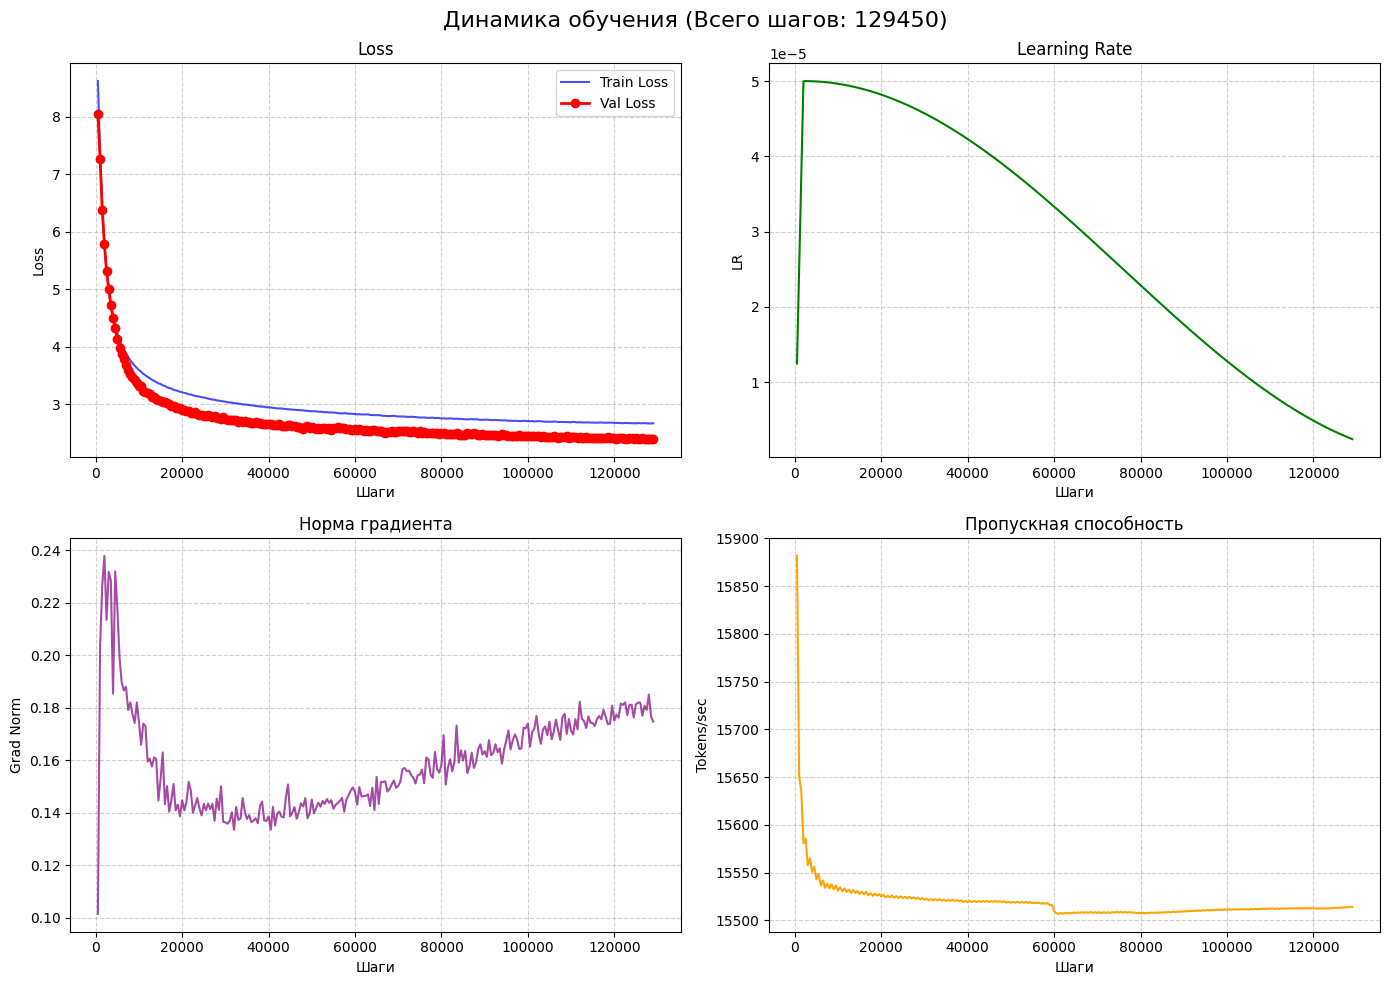

In [7]:
import torch
import gc
import json
import matplotlib.pyplot as plt
from isllm.config import load_config
from isllm.training import set_seed, train

def plot_tensorboard_dashboard(trainer):
    history = trainer.state.log_history
    
    train_steps, train_loss = [], []
    eval_steps, eval_loss = [], []
    lr_steps, lr_values = [], []
    grad_steps, grad_values = [], []
    speed_steps, speeds = [], []

    for log in history:
        step = log.get("step", 0)
        if "loss" in log:
            train_steps.append(step)
            train_loss.append(log["loss"])
        if "eval_loss" in log:
            eval_steps.append(step)
            eval_loss.append(log["eval_loss"])
        if "learning_rate" in log:
            lr_steps.append(step)
            lr_values.append(log["learning_rate"])
        if "grad_norm" in log:
            grad_steps.append(step)
            grad_values.append(log["grad_norm"])
        if "train_tokens_per_second" in log:
            speed_steps.append(step)
            speeds.append(log["train_tokens_per_second"])

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"Динамика обучения (Всего шагов: {trainer.state.global_step})", fontsize=16)

    #  Loss
    if train_steps:
        axes[0, 0].plot(train_steps, train_loss, label="Train Loss", color="blue", alpha=0.7)
    if eval_steps:
        axes[0, 0].plot(eval_steps, eval_loss, label="Val Loss", color="red", marker="o", linewidth=2)
    axes[0, 0].set_title("Loss")
    axes[0, 0].set_xlabel("Шаги")
    axes[0, 0].set_ylabel("Loss")
    axes[0, 0].legend()
    axes[0, 0].grid(True, linestyle="--", alpha=0.6)

    # Learning Rate
    if lr_steps:
        axes[0, 1].plot(lr_steps, lr_values, color="green")
        axes[0, 1].set_title("Learning Rate")
        axes[0, 1].set_xlabel("Шаги")
        axes[0, 1].set_ylabel("LR")
        axes[0, 1].grid(True, linestyle="--", alpha=0.6)

    # Gradient Norm
    if grad_steps:
        axes[1, 0].plot(grad_steps, grad_values, color="purple", alpha=0.7)
        axes[1, 0].set_title("Норма градиента")
        axes[1, 0].set_xlabel("Шаги")
        axes[1, 0].set_ylabel("Grad Norm")
        axes[1, 0].grid(True, linestyle="--", alpha=0.6)

    # Скорость обучения 
    if speed_steps:
        axes[1, 1].plot(speed_steps, speeds, color="orange")
        axes[1, 1].set_title("Пропускная способность")
        axes[1, 1].set_xlabel("Шаги")
        axes[1, 1].set_ylabel("Tokens/sec")
        axes[1, 1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()


gc.collect()
torch.cuda.empty_cache()

CONFIG_PATH = "configs/large.yaml"
config = load_config(CONFIG_PATH)
set_seed(config.train.seed)

SMOKE_STEPS = None
RESUME_FROM = None 

result, trainer = train(config,
                        max_steps_override=SMOKE_STEPS,
                        resume_from_checkpoint=RESUME_FROM,
                        device=None)

print("\nИтог обучения:")
print(json.dumps(result, ensure_ascii=False, indent=2))

plot_tensorboard_dashboard(trainer)

In [15]:
# скачивание модели
from pathlib import Path
import shutil, os
from IPython.display import FileLink, display

save_dir = Path("my_model")
trainer.save_model(save_dir)

if os.path.exists("my_model.zip"): os.remove("my_model.zip")
shutil.make_archive("my_model", "zip", root_dir=save_dir)
print("Размер, МБ:", round(os.path.getsize("my_model.zip")/1024/1024, 1))

display(FileLink("my_model.zip"))

Saving model checkpoint to my_model
Configuration saved in my_model/config.json
Configuration saved in my_model/generation_config.json


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model weights saved in my_model/model.safetensors


Размер, МБ: 315.3


/home/jovyan/work/isllm/my_model.zip